# 02: Exploratory Data Analysis

Each section asks one question, answers it with as few charts as possible, and records the decision it informs (see README → Open Decisions).

 *Code generated w/ help from Claude Code* See `docs/ai_usage.md` for how it was checked.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import data_sources as ds

YEARS = list(range(2014, 2026))   # 2026 excluded: partial year
counties = ds.load_counties()
lower48 = counties[~counties["state"].isin(["AK", "HI", "PR"])]

## 1. How much of the signal is observer effort?

**Question:** Do lanternfly sightings track lanternflies, or just how many people are using iNaturalist?

**Data:** iNaturalist research-grade counts per county-year from GBIF, for all species (*effort*) and for lanternfly (*SLF*). Both come from the same openly licensed subset, so the ratio is like-for-like. GBIF has about 73% of the SLF records the iNaturalist API returns (notebook 01).

**Known limitation:** GBIF's county boundaries merge four independent cities into their same-named county (Baltimore, St. Louis, Franklin VA, Richmond County VA).

In [2]:
effort = ds.fetch_gbif_county_counts(YEARS).rename(columns={"n_obs": "all_obs"})
slf = ds.fetch_gbif_county_counts(YEARS, taxon_key=ds.GBIF_SLF_TAXON_KEY).rename(columns={"n_obs": "slf_obs"})

cy = (effort.merge(slf, on=["fips", "year"], how="left")
            .fillna({"slf_obs": 0})
            .astype({"slf_obs": int, "all_obs": int})
            .merge(lower48[["fips", "state", "county"]], on="fips"))
cy["slf_per_10k"] = 1e4 * cy["slf_obs"] / cy["all_obs"]
print(cy.shape)
cy.describe().round(2)

taxon5157899 2014: 0 observations


(35788, 7)


,year,all_obs,slf_obs,slf_per_10k
count,35788.00,35788.00,35788.00,35788.00
mean,2019.67,1550.98,1.49,3.14
std,3.40,6009.12,23.40,55.58
min,2014.00,1.00,0.00,0.00
25%,2017.00,37.00,0.00,0.00
50%,2020.00,191.00,0.00,0.00
75%,2023.00,870.00,0.00,0.00
max,2025.00,243550.00,1723.00,5882.35


### 1a. Effort and sightings over time

Growth 2016→2025: effort ×13, SLF ×5118


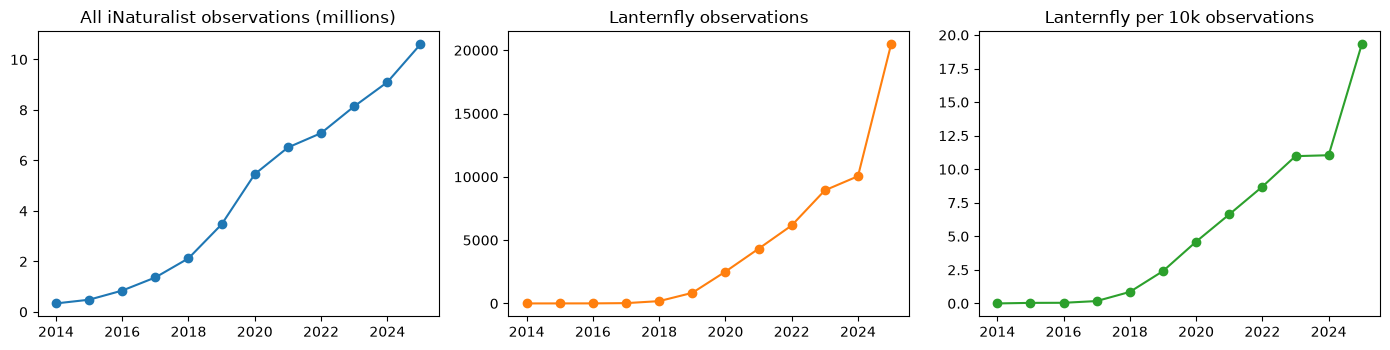

In [3]:
totals = cy.groupby("year")[["all_obs", "slf_obs"]].sum()
totals["slf_per_10k"] = 1e4 * totals["slf_obs"] / totals["all_obs"]

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
(totals["all_obs"] / 1e6).plot(ax=ax[0], marker="o", title="All iNaturalist observations (millions)")
totals["slf_obs"].plot(ax=ax[1], marker="o", color="C1", title="Lanternfly observations")
totals["slf_per_10k"].plot(ax=ax[2], marker="o", color="C2", title="Lanternfly per 10k observations")
for a in ax: a.set_xlabel("")
plt.tight_layout()
print(f"Growth 2016→2025: effort ×{totals.loc[2025, 'all_obs'] / totals.loc[2016, 'all_obs']:.0f}, "
      f"SLF ×{totals.loc[2025, 'slf_obs'] / totals.loc[2016, 'slf_obs']:.0f}")

### 1b. Within counties, how strongly do sightings follow effort?

log-log correlation r = 0.39, slope = 0.51  (n = 1,080)


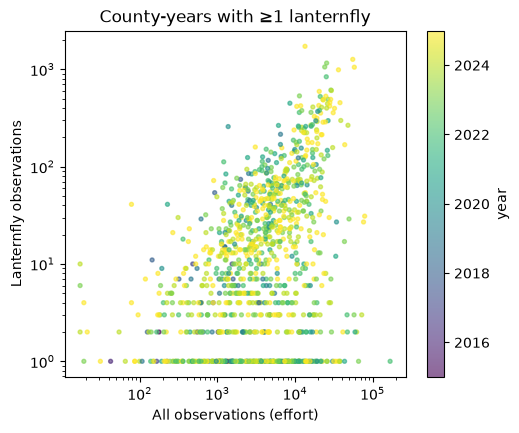

In [4]:
# Only county-years in counties that have ever had SLF; otherwise zeros from
# uninvaded counties dominate.
ever = cy.groupby("fips")["slf_obs"].transform("sum") > 0
sub = cy[ever & (cy["slf_obs"] > 0)]

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sc = ax.scatter(sub["all_obs"], sub["slf_obs"], c=sub["year"], s=8, alpha=.6, cmap="viridis")
ax.set(xscale="log", yscale="log", xlabel="All observations (effort)", ylabel="Lanternfly observations",
       title="County-years with ≥1 lanternfly")
plt.colorbar(sc, label="year")

r = np.corrcoef(np.log(sub["all_obs"]), np.log(sub["slf_obs"]))[0, 1]
slope = np.polyfit(np.log(sub["all_obs"]), np.log(sub["slf_obs"]), 1)[0]
print(f"log-log correlation r = {r:.2f}, slope = {slope:.2f}  (n = {len(sub):,})")

A log-log slope near 1 would mean sightings scale proportionally with effort, which supports modeling counts with an effort *offset* (log(all_obs)) or using the rate directly.

### 1c. Raw counts vs. effort-adjusted rate

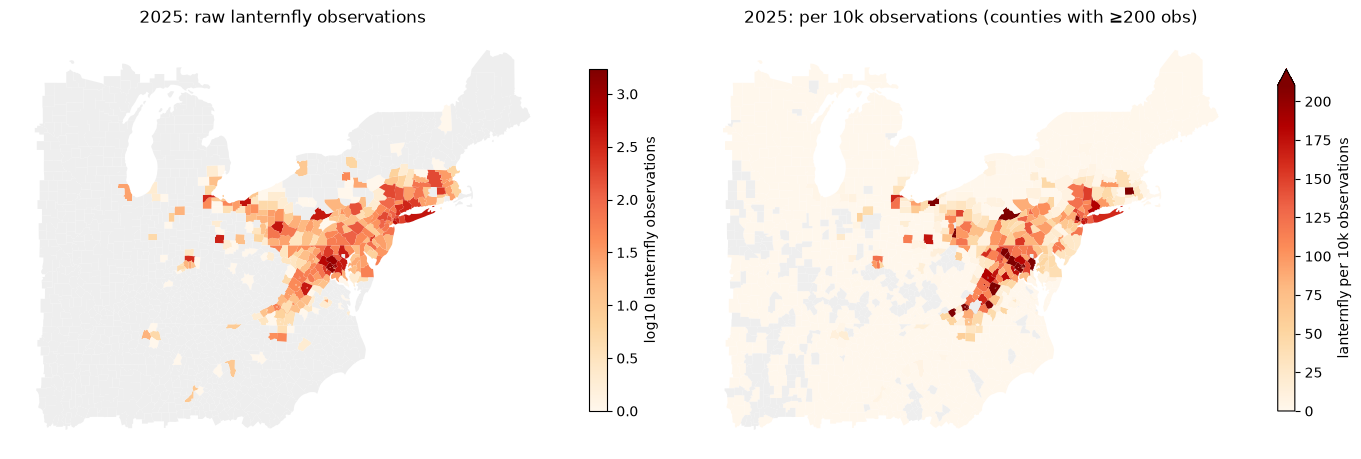

In [5]:
YEAR = 2025
m = lower48.merge(cy[cy["year"] == YEAR], on=["fips", "state", "county"], how="left")
east = m.cx[-92:-66, 33:46]   # region around the invasion

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
east.plot(column=np.log10(east["slf_obs"].where(east["slf_obs"] > 0)), ax=ax[0], legend=True, cmap="OrRd",
          missing_kwds={"color": "#eee"}, legend_kwds={"label": "log10 lanternfly observations", "shrink": .6})
# Rates are noisy where effort is tiny, so require ≥200 observations.
rate = east["slf_per_10k"].where(east["all_obs"] >= 200)
east.plot(column=rate, ax=ax[1], legend=True, cmap="OrRd", vmax=rate.quantile(.98),
          missing_kwds={"color": "#eee"}, legend_kwds={"label": "lanternfly per 10k observations", "shrink": .6})
ax[0].set_title(f"{YEAR}: raw lanternfly observations")
ax[1].set_title(f"{YEAR}: per 10k observations (counties with ≥200 obs)")
for a in ax: a.set_axis_off()
plt.tight_layout()

In [6]:
def top(col, n=10):
    t = cy[(cy["year"] == YEAR) & (cy["all_obs"] >= 200)].nlargest(n, col)
    return t[["state", "county", "all_obs", "slf_obs", "slf_per_10k"]].round(1).reset_index(drop=True)

print(f"Top counties in {YEAR} by raw count:");  display(top("slf_obs"))
print(f"Top counties in {YEAR} by rate:");       display(top("slf_per_10k"))

Top counties in 2025 by raw count:


,state,county,all_obs,slf_obs,slf_per_10k
0,VA,Arlington,13450,1723,1281.0
1,VA,Fairfax,55468,1265,228.1
2,MD,Montgomery,58088,1051,180.9
3,DC,District of Columbia,36290,988,272.3
4,VA,Loudoun,20503,593,289.2
5,NY,New York,24922,529,212.3
6,NY,Kings,28787,491,170.6
7,OH,Cuyahoga,23141,485,209.6
8,NY,Suffolk,28077,455,162.1
9,PA,Allegheny,37991,454,119.5


Top counties in 2025 by rate:


,state,county,all_obs,slf_obs,slf_per_10k
0,VA,Arlington,13450,1723,1281.0
1,VA,Roanoke,894,72,805.4
2,VA,Salem,266,21,789.5
3,VA,Staunton,434,23,530.0
4,WV,Jefferson,3075,159,517.1
5,WV,Brooke,422,17,402.8
6,VA,Albemarle,10523,416,395.3
7,PA,Centre,11832,422,356.7
8,VA,Harrisonburg,1945,57,293.1
9,VA,Loudoun,20503,593,289.2


---

## ToDo
### EDA/Interpretation

- Is effort growth a big enough share of the SLF trend that raw counts are misleading?
- Do the top counties change when switching from counts to rates? What does that say about where lanternflies actually are?
- **Decision:** response variable = raw count with an effort offset, rate, or presence/absence?

In [7]:
ds.PROCESSED.mkdir(parents=True, exist_ok=True)
cy.to_parquet(ds.PROCESSED / "county_year_effort.parquet", index=False)